# Experiment 8: SD 1.5 vs SDXL for Keeping the Design

All my earlier experiments used **Stable Diffusion 1.5** (2022, about 1 billion parameters, trained at 512 px). Most current render tools use newer, larger models. **SDXL** (2023) has a UNet about three times larger, two text encoders and was trained at **1024 px**, so it usually gives sharper, more detailed and more realistic images.

**The question:** with the same setup (Canny ControlNet + img2img, strength 0.6), does SDXL keep the design better or worse than SD 1.5, and what does it cost on a free T4 GPU?

| Variant | Model | Resolution |
|---|---|---|
| **A: SD 1.5** | SD 1.5 + Canny ControlNet | 768×432 (same as my earlier experiments) |
| **B: SDXL at 768** | SDXL + Canny ControlNet | 768×432 (below SDXL's native size) |
| **C: SDXL at 1024** | SDXL + Canny ControlNet | 1024×576 (close to SDXL's native size) |

B separates the effect of the **model** from the effect of the **resolution**: A vs B is the same size with a different model; B vs C is the same model at a different size.

**Fair metrics.** All outputs are resized to 768×432 before measuring, so every variant is compared with the same original. Same prompt, seed (42), steps (25), strength (0.6) and ControlNet scale (1.0) for all.

| Metric | What it tells | Better |
|---|---|---|
| **Edge recall** | Share of the original edges still in the render | higher |
| **SSIM** | Structural similarity with the original | higher |
| **Mean ΔE** | Average color change (CIEDE2000) | lower |
| **CLIP gain** | How much more the render matches the prompt than the original photo does | higher |
| **Sec/image, peak memory** | Cost on a free T4 GPU | lower |

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload room photos
Upload **3 to 5 interior photos** (the same rooms as Experiments 6 and 7 work well). Each photo is center-cropped to 16:9, so nothing is stretched.

In [3]:
import io, gc, time, cv2, numpy as np, pandas as pd
from PIL import Image
from IPython.display import Image as IPImage
from google.colab import files

uploaded = files.upload()
images = sorted(uploaded)

def crop_16_9(img):
    w, h = img.size; target = 16 / 9
    if w / h > target:
        nw = int(h * target); x = (w - nw) // 2; return img.crop((x, 0, x + nw, h))
    nh = int(w / target); y = (h - nh) // 2; return img.crop((0, y, w, y + nh))

photos = {n: crop_16_9(Image.open(name).convert("RGB")) for n, name in enumerate(images, start=1)}
print({n: p.size for n, p in photos.items()})

def show(img, max_w=1600):
    im = img.copy(); im.thumbnail((max_w, max_w))
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=85); display(IPImage(data=buf.getvalue()))

Saving living-room.jpg to living-room.jpg
Saving livspace4.png to livspace4.png
Saving livspace5.png to livspace5.png
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
{1: (1365, 768), 2: (940, 528), 3: (2560, 1440), 4: (1365, 768), 5: (1365, 768)}


## 4. Shared settings

In [4]:
prompt = "photorealistic interior render, light oak wooden floor, white walls, natural daylight"
negative = "blurry, distorted, low quality, deformed"
SEED, STEPS, STRENGTH, CN_SCALE = 42, 25, 0.6, 1.0
MEASURE = (768, 432)                                    # every output is measured at this size

VARIANTS = {"A: SD 1.5 (768)": ("sd15", (768, 432)),
            "B: SDXL (768)":   ("sdxl", (768, 432)),
            "C: SDXL (1024)":  ("sdxl", (1024, 576))}

def canny_map(img):
    e = cv2.Canny(np.array(img), 100, 200)
    return Image.fromarray(np.stack([e] * 3, axis=-1))

def free():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

## 5. Load a model, run it, free it
The two models are loaded one after the other, so the T4's 15 GB is enough. SDXL uses the **fp16-fix VAE**: the original SDXL VAE produces black or broken images in float16.

In [5]:
from diffusers import (ControlNetModel, AutoencoderKL,
                       StableDiffusionControlNetImg2ImgPipeline, StableDiffusionXLControlNetImg2ImgPipeline)

def load(model):
    if model == "sd15":
        cn = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16)
        pipe = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
            "stable-diffusion-v1-5/stable-diffusion-v1-5", controlnet=cn,
            torch_dtype=torch.float16, safety_checker=None)
    else:
        cn = ControlNetModel.from_pretrained("diffusers/controlnet-canny-sdxl-1.0",
                                             torch_dtype=torch.float16, variant="fp16")
        vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
        pipe = StableDiffusionXLControlNetImg2ImgPipeline.from_pretrained(
            "stabilityai/stable-diffusion-xl-base-1.0", controlnet=cn, vae=vae,
            torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.to("cuda"); pipe.set_progress_bar_config(disable=True)
    return pipe

def render(pipe, photo, size):
    room = photo.resize(size, Image.LANCZOS)
    return pipe(prompt, negative_prompt=negative, image=room, control_image=canny_map(room),
                strength=STRENGTH, num_inference_steps=STEPS, guidance_scale=7.5,
                controlnet_conditioning_scale=CN_SCALE, width=size[0], height=size[1],
                generator=torch.manual_seed(SEED)).images[0]

outputs, perf = {}, []
for model in ["sd15", "sdxl"]:
    free(); t = time.time()
    pipe = load(model)
    load_gb = torch.cuda.memory_allocated() / 1e9
    print(f"{model}: loaded in {time.time() - t:.0f} s, {load_gb:.1f} GB on the GPU")
    for vname, (m, size) in VARIANTS.items():
        if m != model: continue
        render(pipe, photos[1], size)                  # warm-up, not timed
        for n, photo in photos.items():
            torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
            outputs[(vname, n)] = render(pipe, photo, size)
            torch.cuda.synchronize()
            perf.append({"variant": vname, "room": n, "sec/image": time.time() - t,
                         "peak GB": torch.cuda.max_memory_allocated() / 1e9, "model GB": load_gb})
        print(f"  {vname} done")
    del pipe; free()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (15 outputs left out)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

sdxl: loaded in 245 s, 9.6 GB on the GPU
  B: SDXL (768) done
  C: SDXL (1024) done


## 6. Look at the results
First row: whole image (original | A | B | C). Second row: a zoomed crop from the center, taken from each image **at its own resolution**, so SDXL at 1024 shows its extra detail.

room 1: original | A: SD 1.5 (768) | B: SDXL (768) | C: SDXL (1024)


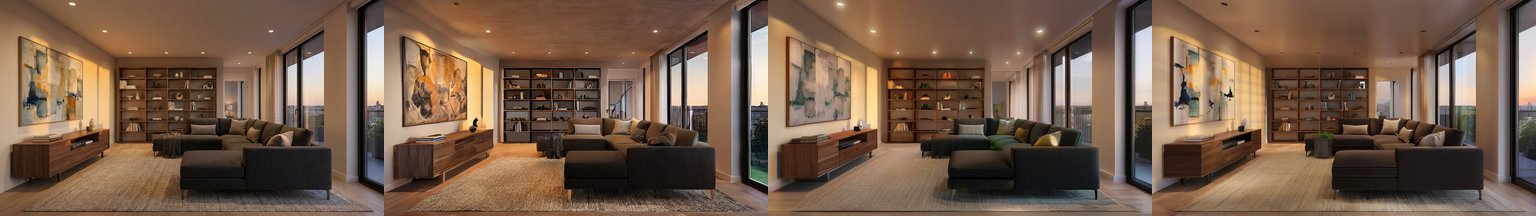

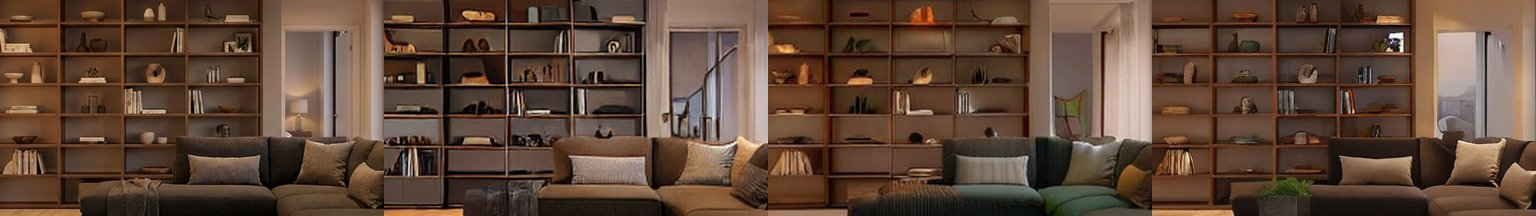

room 2: original | A: SD 1.5 (768) | B: SDXL (768) | C: SDXL (1024)


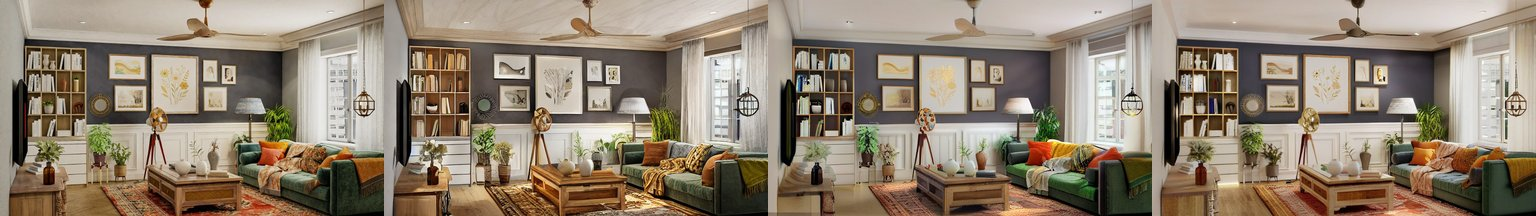

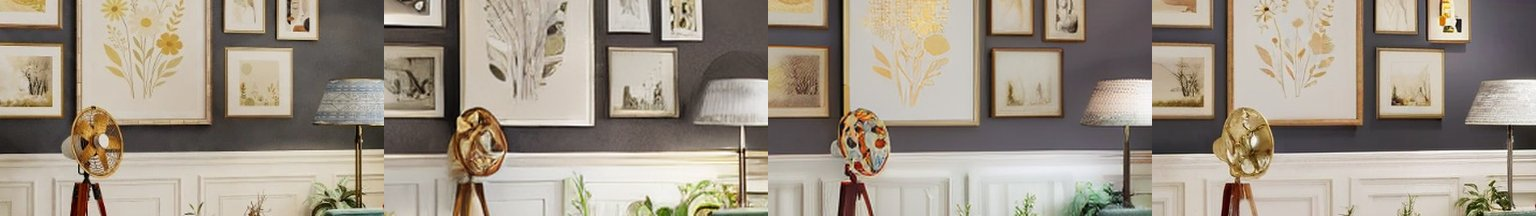

room 3: original | A: SD 1.5 (768) | B: SDXL (768) | C: SDXL (1024)


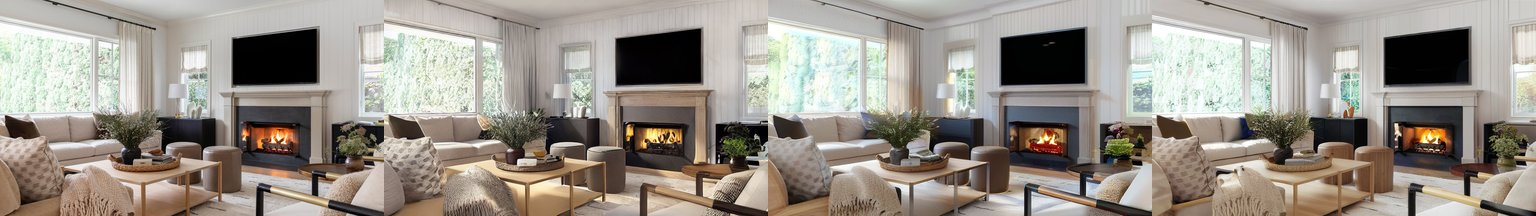

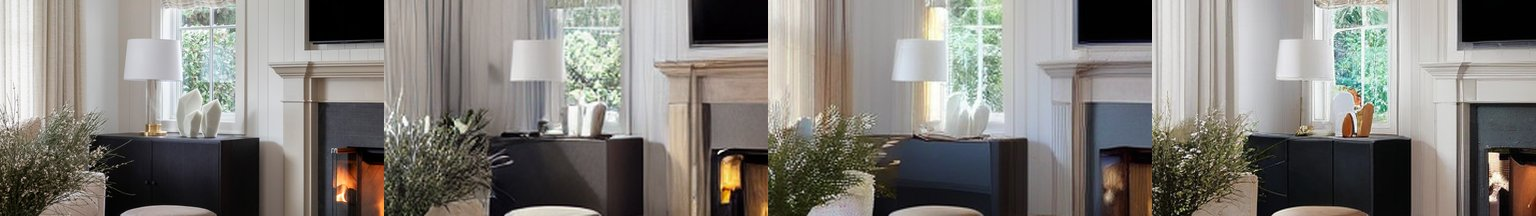

room 4: original | A: SD 1.5 (768) | B: SDXL (768) | C: SDXL (1024)


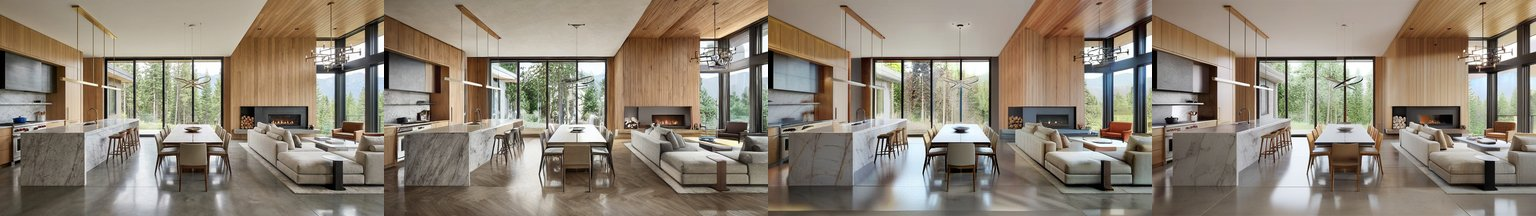

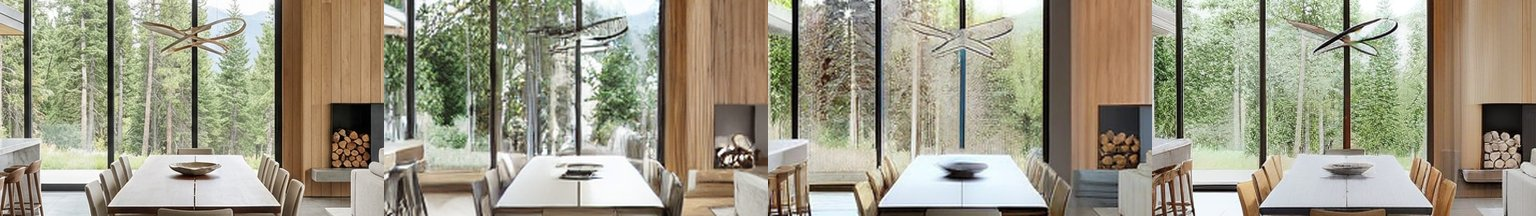

room 5: original | A: SD 1.5 (768) | B: SDXL (768) | C: SDXL (1024)


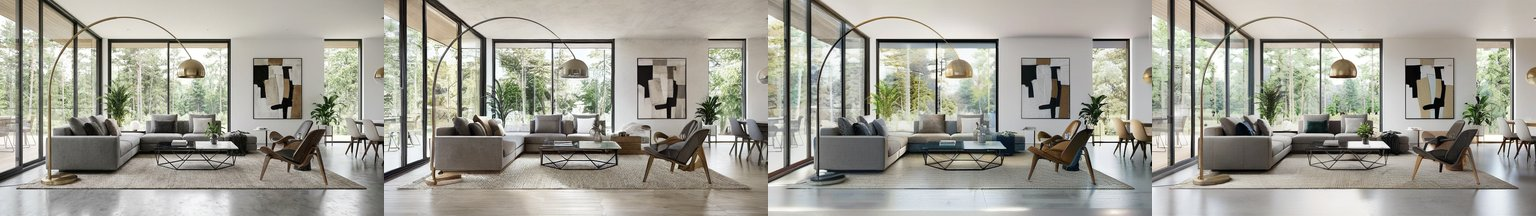

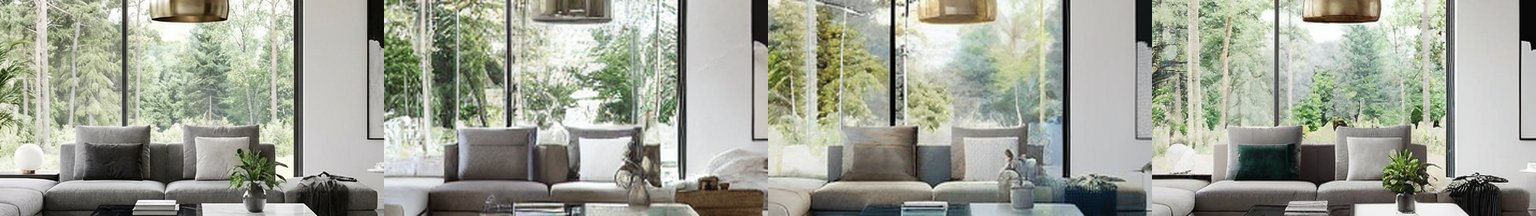

In [6]:
NAMES = list(VARIANTS)
def strip(imgs, w, h):
    row = Image.new("RGB", (w * len(imgs), h), "white")
    for i, im in enumerate(imgs): row.paste(im.resize((w, h), Image.LANCZOS), (i * w, 0))
    return row

def center_crop(img, frac=0.35):
    w, h = img.size; cw, ch = int(w * frac), int(h * frac)
    return img.crop(((w - cw) // 2, (h - ch) // 2, (w + cw) // 2, (h + ch) // 2))

for n in photos:
    orig = photos[n].resize(MEASURE, Image.LANCZOS)
    imgs = [orig] + [outputs[(v, n)] for v in NAMES]
    full = strip(imgs, 384, 216); crops = strip([center_crop(i) for i in [photos[n]] + imgs[1:]], 384, 216)
    print(f"room {n}: original | " + " | ".join(NAMES))
    show(full); show(crops)
    full.save(f"exp8_room{n}_full.jpg", quality=90); crops.save(f"exp8_room{n}_crops.jpg", quality=90)

## 7. Measure (all at 768×432)

In [7]:
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2lab, deltaE_ciede2000
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda")
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def clip_score(img):
    x = clip_proc(text=[prompt], images=img, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        im = clip.visual_projection(clip.vision_model(pixel_values=x["pixel_values"]).pooler_output)
        tx = clip.text_projection(clip.text_model(input_ids=x["input_ids"], attention_mask=x["attention_mask"]).pooler_output)
    im = im / im.norm(dim=-1, keepdim=True); tx = tx / tx.norm(dim=-1, keepdim=True)
    return float((im @ tx.T).item() * 100)

def gray(a): return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
def edge_recall(orig, rend):
    e_o = cv2.Canny(orig, 100, 200) > 0
    e_r = cv2.dilate((cv2.Canny(rend, 100, 200) > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (e_o & e_r).sum() / max(e_o.sum(), 1)

rows = []
for n in photos:
    orig_img = photos[n].resize(MEASURE, Image.LANCZOS); orig = np.array(orig_img); base_clip = clip_score(orig_img)
    for v in NAMES:
        r_img = outputs[(v, n)].resize(MEASURE, Image.LANCZOS); r = np.array(r_img)
        rows.append({"variant": v, "room": n,
                     "edge recall ↑": edge_recall(orig, r),
                     "SSIM ↑": ssim(gray(orig), gray(r)),
                     "ΔE ↓": float(deltaE_ciede2000(rgb2lab(orig), rgb2lab(r)).mean()),
                     "CLIP gain ↑": clip_score(r_img) - base_clip})

df = pd.DataFrame(rows).merge(pd.DataFrame(perf), on=["variant", "room"])
summary = df.groupby("variant").mean(numeric_only=True).drop(columns="room").reindex(NAMES)
display(summary.round(3))
display(df.pivot_table(index="room", columns="variant", values="edge recall ↑").reindex(columns=NAMES).round(3))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,edge recall ↑,SSIM ↑,ΔE ↓,CLIP gain ↑,sec/image,peak GB,model GB
variant,,,,,,,
A: SD 1.5 (768),0.957,0.538,9.450,0.833,4.963,3.755,2.895
B: SDXL (768),0.876,0.624,8.281,0.592,8.520,10.479,9.625
C: SDXL (1024),0.894,0.689,7.001,1.753,13.398,11.134,9.625


variant,A: SD 1.5 (768),B: SDXL (768),C: SDXL (1024)
room,,,
1,0.952,0.856,0.859
2,0.975,0.941,0.931
3,0.938,0.791,0.852
4,0.953,0.921,0.914
5,0.968,0.873,0.912


## 8. Chart

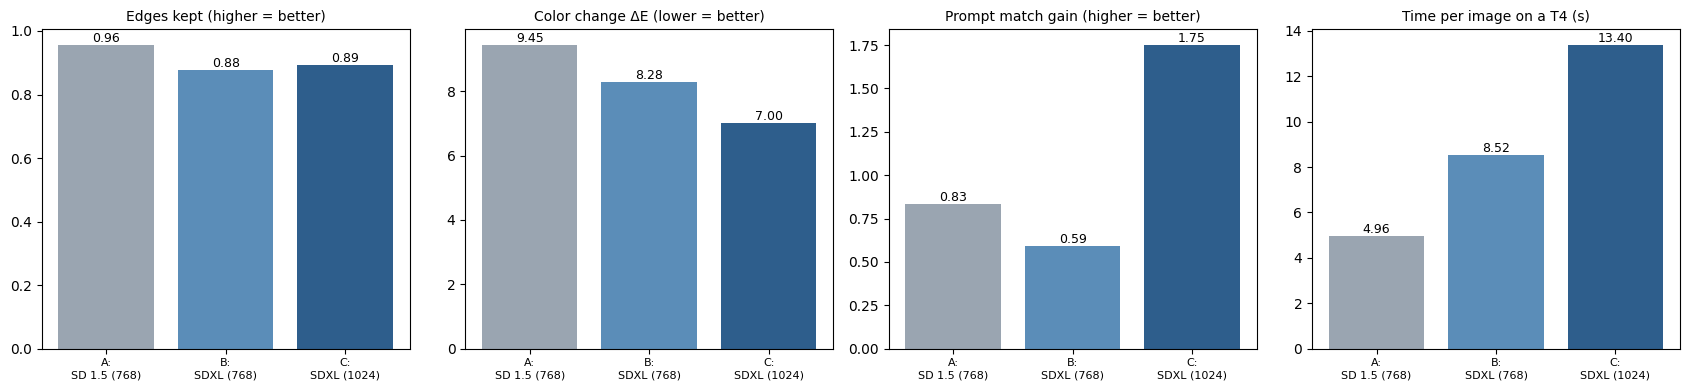

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
colors = ["#9AA5B1", "#5B8DB8", "#2E5E8C"]
labels = [v.replace(": ", ":\n") for v in NAMES]
for ax, col, title in zip(axes, ["edge recall ↑", "ΔE ↓", "CLIP gain ↑", "sec/image"],
                          ["Edges kept (higher = better)", "Color change ΔE (lower = better)",
                           "Prompt match gain (higher = better)", "Time per image on a T4 (s)"]):
    ax.bar(labels, summary[col], color=colors)
    for i, v in enumerate(summary[col]): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig("exp8_sd15_vs_sdxl.png", dpi=150); plt.show()

**What I saw.**
- **A (SD 1.5 at 768):** keeps edges best (edge recall 0.957, best in all five rooms), because the SD 1.5 Canny ControlNet follows the edge map very closely. But it changes colors and small objects most (ΔE 9.5, SSIM 0.54): a blue painting turned orange, a sunflower painting became a branch drawing, a door became a staircase. The cheapest option: 5.0 s per image, 3.8 GB.
- **B (SDXL at 768):** the weakest overall. It keeps fewer edges than SD 1.5 (0.876) and follows the prompt least (CLIP gain 0.59). SDXL below its native resolution loses its advantage.
- **C (SDXL at 1024):** the best for colors and overall look (SSIM 0.689, ΔE 7.0) and the best prompt match (CLIP gain 1.75, twice SD 1.5). Paintings and shelf objects stayed closest to the original. But it keeps fewer edges than SD 1.5 (0.894), it still invents some things (a plant on a table, a dark cushion turned green), and in the open-plan room it did not change the floor at all. It is 2.7× slower (13.4 s) and needs 3× the memory (11.1 GB peak).

**Result.** Neither model is better on every axis. SD 1.5 keeps geometry more strictly; SDXL at its native size keeps colors and objects better and follows the prompt better. The answer depends on what "keeping the design" means for the task: lines and layout (SD 1.5), or materials, colors and artwork (SDXL). SDXL should be run at its native resolution: at 768 it was worse than SD 1.5 on most metrics. On a free T4, SDXL fits, but uses most of the 15 GB.

**Limits.** Five rooms and one seed. The ControlNet scale (1.0) and strength (0.6) were chosen for SD 1.5 in Experiment 1; the SDXL Canny ControlNet may follow edges more closely at a higher scale, so the edge gap could be partly a tuning effect. Measuring at 768×432 hides part of SDXL's extra detail, which the crops show instead. CLIP looks at the whole image and is a rough measure of prompt match.

## Download

In [9]:
df.to_csv("exp8_metrics.csv", index=False)
!zip -q exp8_results.zip exp8_*.jpg exp8_*.png exp8_metrics.csv
files.download("exp8_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>